# Exercise 1
Nico Reiterer - 5191 2112

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1.1. - Approximation of the integral

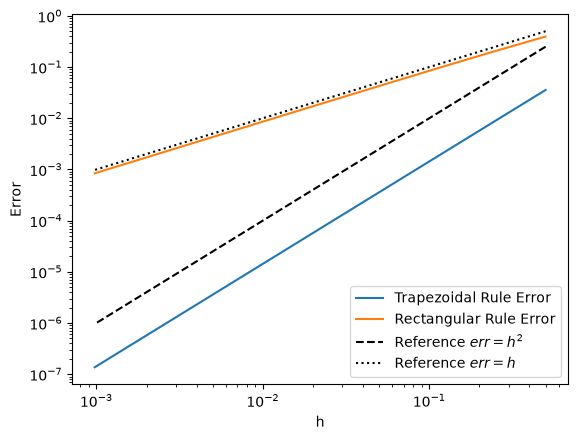

In [ ]:
def T(h: float, f: callable) -> float:
    """
    Implementation of the trapezoidal rule for numerical integration.
    """
    N = round(1 / h)

    # x_i = i * h
    x = np.arange(0, N+1) * h # N + 1 because the last point is i + 1, so not N-1, but N ..

    y = f(x)
    h = 1 / N

    
    return h * (0.5 * y[0] + y[1:-1].sum() + 0.5 * y[-1])

def R(h: float, f:callable) -> float:
    """
    IMplementation of the box rule for numerical integration.
    """
    N = round(1 / h)

    # x_i = i * h
    x = np.arange(0, N) * h

    y = f(x)
    h = 1 / N
    
    return h * y.sum()

def f(x: np.ndarray) -> np.ndarray:
    """
    Function to be integrated in 1b.
    """
    return np.exp(x)

def N(i: int) -> float:
    return 2 ** (i + 1)

def calc_1b_error(h: np.ndarray, f: callable, appr: callable) -> np.ndarray:
    """
    Calculate the error for the trapezoidal rule.
    """

    err = np.zeros_like(h)
    for i in range(len(h)):
        err[i] = np.exp(1) - 1 - appr(h[i], f)

    return err

h = 1 / N(np.arange(0, 10))
plt.loglog(h, np.abs(calc_1b_error(h, f, T)), label="Trapezoidal Rule Error")
plt.loglog(h, np.abs(calc_1b_error(h, f, R)), label="Rectangular Rule Error")
plt.loglog(h, h**2, "k--", label="Reference $err = h^2$")
plt.loglog(h, h, "k:", label="Reference $err = h$")
plt.xlabel("h")
plt.ylabel("err")
plt.legend()
plt.show()

**Does the true error behave like $Ch^2$?**

Yes, the true error behaves like $Ch^2$ for the trapezoidal rule. The error decreases quadratically as the step size $h$ decreases, which is I guess consistent with the theory!

**Do the same thing for the box rule as well. What error behaviour do you see?**

We see a linear decrease in the error as the step size $h$ decreases.

## 1.2. - Design of an error estimator

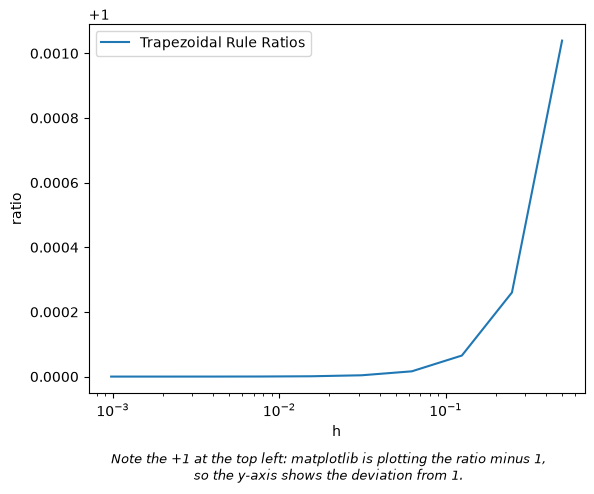

In [29]:
# a) Making the Ansatz
def C(h: float, f: callable, T: callable) -> float:
    """
    Calculate the constant C for the trapezoidal rule.
    """
    y = 1 / h**2 * 4 / 3 * (T(h/2, f) - T(h, f))
    return y

def E(h: float, f: callable, T: callable) -> float:
    """
    Calculate the error for the trapezoidal rule, which is C * h^2, hence taking the same as above but w/out the 1/h^2 factor.
    """
    y = 4 / 3 * (T(h/2, f) - T(h, f))
    return y

# b) Computing the ratios r(i) := err(i) / E(h(i))
def calc_ratios(h: np.ndarray, f: callable, appr: callable) -> np.ndarray:
    """
    Calculate the ratios of the true error to estimated error: 
        r(i) := err(i) / E(h(i)) for the trapezoidal rule.
    """

    err = calc_1b_error(h, f, appr)
    E_vals = np.array([E(h_i, f, appr) for h_i in h])
    return err / E_vals

h = 1 / N(np.arange(0, 10))
plt.semilogx(h, calc_ratios(h, f, T), label="Trapezoidal Rule Ratios")
plt.xlabel("h")
plt.ylabel("ratio")
plt.figtext(
    0.5, -0.01,
    "Note the +1 at the top left: matplotlib is plotting the ratio minus 1,\n"
    "so the y-axis shows the deviation from 1.",
    ha="center", va="top", fontsize=9, style="italic",
)
plt.legend()
plt.show()

So we can see quite cleary that the smaller h gets (so the bigger N gets), the smaller the ratio of the actual error to the estimated error gets!

## 1.3. - Some functions to inspect

In [ ]:
def f_1(C: float, h: float, alpha: float) -> float:
    """
    Function 1 from 1.3. h -> C * h ** alpha 
        >> Here I expect a straight line in the log-log plot, with slope alpha.
    """
    return C * h**alpha

def f_2(C: float, N: float, b: float) -> float:
    """
    Function 2 from 1.3. N -> C * exp(-b * N)
        >> Here I expect a straight line in the semi-logy plot, with slope -b.
    """
    return C * np.exp(-b * N)

def f_3(C: float, h: float, b: float) -> float:
    """
    Function 3 from 1.3. h -> C * exp(-b / h)
        >> Here you can see that ln f is not linear in h or in ln h, but in 1/h 
    """
    return C * np.exp(-b / h)

def f_4(C: float, h: float, b: float) -> float:
    """
    Function 4 from 1.3. h -> C * exp(-b / h**2)
        >> So this is similar to f_3, but now the slope is -b in 1/h**2, so we expect a straight line in the semi-logy plot of f against 1/h**2.
    """
    return C * np.exp(-b / h**2)



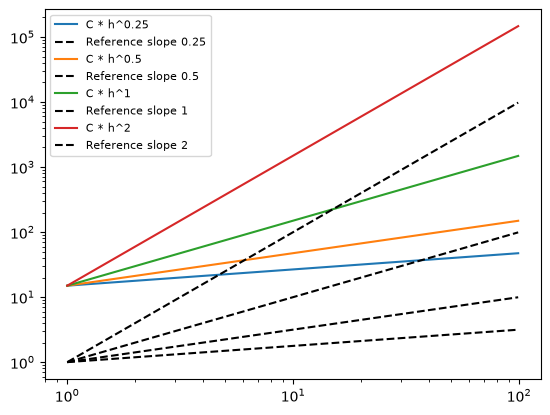

In [41]:
h = np.arange(1, 100)
for i in [0.25, 0.5, 1, 2]:
    plt.loglog(h, f_1(15, h, i), label=f"C * h^{i}")
    
    # plotting the slope which is essentially just based on the alpha...
    # taking the log of both sides gives us log(f) = log(C) + alpha * log(h), so the slope is alpha.
    plt.loglog(h, h**i, "k--", label=f"Reference slope {i}")

plt.legend(fontsize=8)
plt.show()

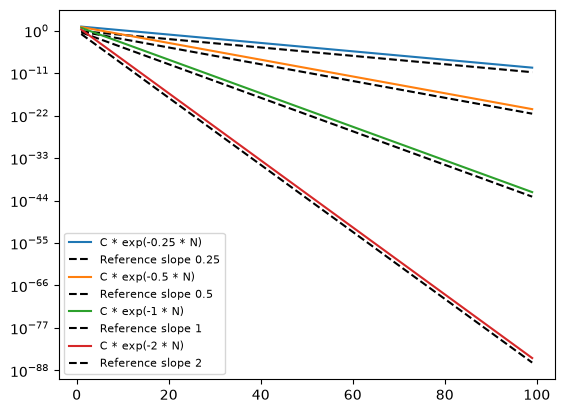

In [ ]:
h = np.arange(1, 100)
for i in [0.25, 0.5, 1, 2]:
    plt.semilogy(h, f_2(15, h, i), label=f"C * exp(-{i} * N)")
    
    # plotting the slope which is essentially just based on the alpha...
    # taking the log of the y-axis gives us N -> log(f) = log(C) - b * N, so the slope is -b.
    plt.semilogy(h, np.exp(-i * h), "k--", label=f"Reference slope {i}")

plt.legend(fontsize=8)
plt.show()

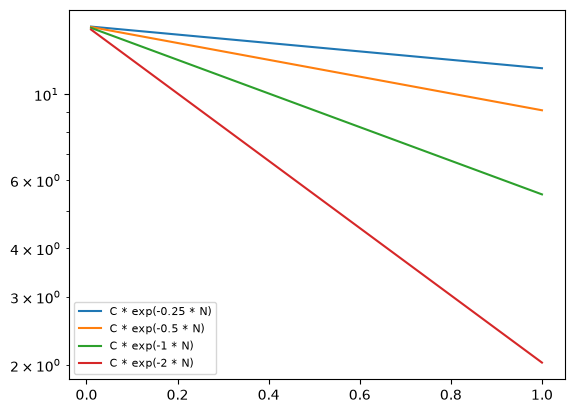

In [77]:
h = np.arange(1, 100)
for i in [0.25, 0.5, 1, 2]:
    plt.semilogy(1/h, f_3(15, h, i), label=f"C * exp(-{i} * N)")
    
    # Function 3 from 1.3. h -> C * exp(-b / h)
    # applying the log to both sides gives us log(f) = log(C) - b * 1/h, so the slope is -b if we plot log(f) against 1/h.

plt.legend(fontsize=8, loc="lower left")
plt.show()

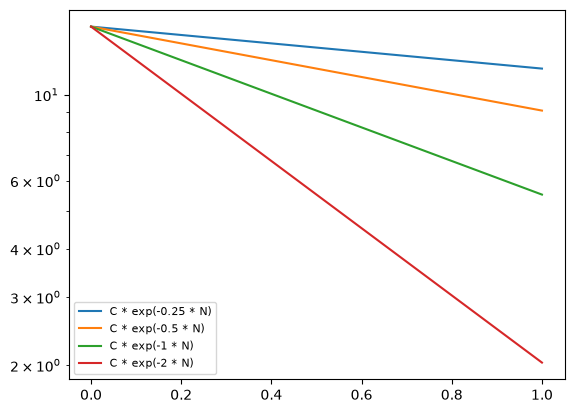

In [ ]:
h = np.arange(1, 100)
for i in [0.25, 0.5, 1, 2]:
    plt.semilogy(1/h**2, f_4(15, h, i), label=f"C * exp(-{i} * N)")

    # Function 4 from 1.3. h -> C * exp(-b / h**2)
    # applying the log to both sides gives us log(f) = log(C) - b * 1/h**2, so the slope is -b if we plot log(f) against 1/h**2.

plt.legend(fontsize=8, loc="lower left")
plt.show()